# IN1102 — Questão 2: classificadores na segunda versão do Spambase

**Objetivo:** prever os rótulos de clusters de objetos encontrados pelo Double K-means na Questão 1 (`K* = 2`). Este notebook trata apenas da **segunda versão** da variável resposta, como você pediu.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

# Caminho da pasta no Google Drive
PASTA_PROJETO = Path(
    "/content/drive/MyDrive/Projeto_emails_ML"
)

# Verificar se a pasta existe
if PASTA_PROJETO.exists():
    print("Pasta encontrada! ✅")

    print("\nArquivos disponíveis:")
    for arquivo in PASTA_PROJETO.iterdir():
        print(arquivo.name)
else:
    print("Pasta não encontrada. Verifique o nome e o caminho.")

Pasta encontrada! ✅

Arquivos disponíveis:
data
output
double_kmeans_spambase.ipynb
double_kmeans_spambase.R
grafico_clusters_11_variaveis.png
resultados_parzen.csv
intervalos_confianca_parzen.csv
resultados_parzen_aninhado.csv
curva_aprendizagem_parzen.csv
cl_Kstar.csv
double_kmeans_spambase_export.R
output_exportacao


In [ ]:
# Procurar arquivos relacionados ao Spambase e aos clusters
termos = [
    "spambase.data",
    "clusters_de_variaveis.csv",
    "clusters_objetos.csv",
    "resultados_KH.csv",
    "ari.txt"
]

print("Arquivos encontrados:\n")

for caminho in PASTA_PROJETO.rglob("*"):
    if caminho.is_file():
        if any(termo.lower() in caminho.name.lower()
               for termo in termos):
            print(caminho)

Arquivos encontrados:

/content/drive/MyDrive/Projeto_emails_ML/data/spambase.data
/content/drive/MyDrive/Projeto_emails_ML/output/resultados_KH.csv
/content/drive/MyDrive/Projeto_emails_ML/output/clusters_de_variaveis.csv
/content/drive/MyDrive/Projeto_emails_ML/output/ari.txt
/content/drive/MyDrive/Projeto_emails_ML/output_exportacao/resultados_KH.csv
/content/drive/MyDrive/Projeto_emails_ML/output_exportacao/ari.txt
/content/drive/MyDrive/Projeto_emails_ML/output_exportacao/clusters_de_variaveis.csv


In [ ]:
import pandas as pd

arquivos_clusters = list(
    PASTA_PROJETO.rglob("clusters_de_variaveis.csv")
)

if arquivos_clusters:
    arquivo_clusters = arquivos_clusters[0]
    df_clusters = pd.read_csv(arquivo_clusters)

    print("Arquivo:", arquivo_clusters)
    display(df_clusters.head())
    print("\nDimensões:", df_clusters.shape)
else:
    print("Não encontrei clusters_de_variaveis.csv.")

Arquivo: /content/drive/MyDrive/Projeto_emails_ML/output/clusters_de_variaveis.csv


,variavel,cluster_var
0,word_freq_make,1
1,word_freq_address,1
2,word_freq_all,1
3,word_freq_3d,1
4,word_freq_our,1



Dimensões: (57, 2)


In [ ]:
import pandas as pd

arquivo_resultados = (
    PASTA_PROJETO / "output" / "resultados_KH.csv"
)

df_resultados = pd.read_csv(arquivo_resultados)

display(df_resultados)
print("Colunas disponíveis:", df_resultados.columns.tolist())

,K,H,f,pct_var,execucoes_no_melhor,f_drclust,Sil
0,2,1,5742.003495,2.189933,100,NaN,0.296094
1,2,2,17766.439381,6.775911,7,NaN,0.659631
2,3,1,7841.282494,2.990573,100,NaN,0.251468
3,3,2,22878.368760,8.725541,7,NaN,0.245379
4,3,3,27817.153465,10.609136,15,NaN,0.142570
5,4,1,8976.369098,3.423482,100,NaN,0.048426
6,4,2,28892.016913,11.019076,53,NaN,0.242797
7,4,3,33733.223022,12.865455,18,NaN,0.161961
8,4,4,34987.645490,13.343877,1,NaN,0.158469


Colunas disponíveis: ['K', 'H', 'f', 'pct_var', 'execucoes_no_melhor', 'f_drclust', 'Sil']


In [ ]:
# Procurar o script original do Double K-means
scripts = list(PASTA_PROJETO.rglob("double_kmeans_spambase.R"))

if scripts:
    SCRIPT_R = scripts[0]
    print("Script encontrado:", SCRIPT_R)

    codigo_r = SCRIPT_R.read_text(encoding="utf-8")

    # Exibir linhas que podem mostrar como os clusters são calculados
    for numero, linha in enumerate(codigo_r.splitlines(), start=1):
        if any(palavra in linha.lower() for palavra in [
            "cluster", "best", "melhor", "write.csv",
            "silhouette", "sil", "k_star", "h_star",
            "cl_star", "labels"
        ]):
            print(f"{numero}: {linha}")
else:
    print("Não encontrei o script R. Vamos procurar o notebook original.")

Script encontrado: /content/drive/MyDrive/Projeto_emails_ML/double_kmeans_spambase.R
11: ##     melhor execução segundo a FUNÇÃO OBJETIVO.
12: ##  3. Para cada um dos 9 pares (K,H) calcula a silhueta média (Sil) da
13: ##     partição de OBJETOS, faz o gráfico Sil x (K,H) e escolhe
14: ##             (K*, H*) = arg max Sil(K,H).
16: ##     com K* clusters e o rótulo a priori (spam / não-spam), e comenta.
17: ##  5. Para o melhor resultado com K*, mostra:
33: ##  silhueta, o ARI e a curva de convergência vêm TODOS da MESMA execução —
37: ##  igual (ou melhor) que a do pacote.
40: library(cluster)   # cluster::silhouette  -> silhueta de cada objeto
82: ## confusão). O algoritmo nunca enxerga esse rótulo — clustering é não
115: ##  ao mesmo tempo, as LINHAS (em K clusters de objetos) e as COLUNAS (em H
116: ##  clusters de variáveis). Isso produz uma "matriz de blocos": cada bloco é o
117: ##  cruzamento de um cluster de objetos com um cluster de variáveis, e é
123: ##    U  (n x K) : par

In [ ]:
notebooks = list(PASTA_PROJETO.rglob("*.ipynb"))

for notebook in notebooks:
    print(notebook)

/content/drive/MyDrive/Projeto_emails_ML/double_kmeans_spambase.ipynb


In [ ]:
import json
from pathlib import Path

arquivo_notebook = (
    Path("/content/drive/MyDrive/Projeto_emails_ML")
    / "double_kmeans_spambase.ipynb"
)

with open(arquivo_notebook, "r", encoding="utf-8") as f:
    notebook = json.load(f)

termos = [
    "cl_star",
    "clusters_objetos",
    "resultados_KH",
    "which.max",
    "Kstar",
    "Hstar",
    "write.csv",
    "to_csv",
]

for i, celula in enumerate(notebook["cells"]):
    codigo = "".join(celula.get("source", []))

    encontrados = [
        termo for termo in termos
        if termo.lower() in codigo.lower()
    ]

    if encontrados:
        print(f"\n{'=' * 60}")
        print(f"Célula {i} | Tipo: {celula['cell_type']}")
        print("Termos encontrados:", ", ".join(encontrados))
        print("-" * 60)
        print(codigo[:5000])


Célula 5 | Tipo: code
Termos encontrados: which.max
------------------------------------------------------------
##
##  IDEIA GERAL
##  -----------
##  O k-means comum agrupa apenas as LINHAS (objetos). O double k-means agrupa,
##  ao mesmo tempo, as LINHAS (em K clusters de objetos) e as COLUNAS (em H
##  clusters de variáveis). Isso produz uma "matriz de blocos": cada bloco é o
##  cruzamento de um cluster de objetos com um cluster de variáveis, e é
##  resumido por um único número, o seu protótipo (a média do bloco).
##
##  NOTAÇÃO (a mesma do artigo de Vichi)
##  ------------------------------------
##    X  (n x J) : dados padronizados
##    U  (n x K) : partição dos objetos.   U[i,k] = 1 se o objeto i está no cluster k
##    V  (J x H) : partição das variáveis. V[j,h] = 1 se a variável j está no cluster h
##    G  (K x H) : matriz de protótipos dos blocos (o "Ybar" do artigo);
##                 G[k,h] = média de X no bloco (objetos do cluster k) x (variáveis do cluster h)
##
##

In [ ]:
import json
from pathlib import Path

arquivo_notebook = Path(
    "/content/drive/MyDrive/Projeto_emails_ML/double_kmeans_spambase.ipynb"
)

with open(arquivo_notebook, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, celula in enumerate(nb["cells"]):
    if celula["cell_type"] == "code":
        for saida in celula.get("outputs", []):
            texto = "".join(saida.get("text", []))
            if "K*" in texto or "FIM." in texto:
                print(f"\n--- Célula {i} ---")
                print(texto[:2500])


--- Célula 11 ---

>> (K*, H*) = (2, 2)  com Sil = 0.6596 <<


--- Célula 13 ---

ARI (double k-means com K*=2  vs  rótulo a priori spam/não-spam) = -0.0049


--- Célula 15 ---

== i) Matriz de protótipos dos blocos G (K* x H*) ==


--- Célula 15 ---

FIM.



In [ ]:
from pathlib import Path
import shutil

pasta = Path("/content/drive/MyDrive/Projeto_emails_ML")
script = pasta / "double_kmeans_spambase.R"

print("Rscript disponível:", shutil.which("Rscript"))
print("Script encontrado:", script.exists())

if script.exists():
    linhas = script.read_text(encoding="utf-8").splitlines()

    for i, linha in enumerate(linhas):
        if any(
            termo in linha
            for termo in ["cl_star", "out_dir", "Kstar", "Hstar"]
        ):
            inicio = max(0, i - 2)
            fim = min(len(linhas), i + 3)

            print(f"\n--- Linhas {inicio + 1} a {fim} ---")
            for j in range(inicio, fim):
                print(f"{j + 1}: {linhas[j]}")

Rscript disponível: /usr/bin/Rscript
Script encontrado: True

--- Linhas 47 a 51 ---
47:   stop("Execute o script a partir da pasta do projeto (onde existe data/spambase.data).")
48: 
49: out_dir <- "output"
50: dir.create(out_dir, showWarnings = FALSE)
51: 

--- Linhas 48 a 52 ---
48: 
49: out_dir <- "output"
50: dir.create(out_dir, showWarnings = FALSE)
51: 
52: 

--- Linhas 425 a 429 ---
425: cat("\n== Resumo por par (K,H) ==\n")
426: print(resumo, row.names = FALSE)
427: write.csv(resumo, file.path(out_dir, "resultados_KH.csv"), row.names = FALSE)
428: write.csv(do.call(rbind, todas_f), file.path(out_dir, "f_das_100_execucoes.csv"), row.names = FALSE)
429: 

--- Linhas 426 a 430 ---
426: print(resumo, row.names = FALSE)
427: write.csv(resumo, file.path(out_dir, "resultados_KH.csv"), row.names = FALSE)
428: write.csv(do.call(rbind, todas_f), file.path(out_dir, "f_das_100_execucoes.csv"), row.names = FALSE)
429: 
430: 

--- Linhas 444 a 448 ---
444:        title = "Silhueta média por

In [ ]:
from pathlib import Path
import subprocess

pasta = Path("/content/drive/MyDrive/Projeto_emails_ML")
original = pasta / "double_kmeans_spambase.R"
copia = pasta / "double_kmeans_spambase_export.R"

# Ler o script original
codigo = original.read_text(encoding="utf-8")

# Salvar os novos resultados em uma pasta separada
codigo = codigo.replace(
    'out_dir <- "output"',
    'out_dir <- "output_exportacao"',
    1
)

# Encontrar o ponto em que os clusters dos e-mails são recuperados
linha = "cl_star <- resultados[[idx_star]]$cl"

if linha not in codigo:
    raise ValueError(
        "Não encontrei a linha de cl_star. "
        "O script original não foi alterado."
    )

# Acrescentar a exportação dos rótulos
adicional = linha + '''

# Exportar o cluster de cada e-mail e seu rotulo original
write.csv(
  data.frame(
    email_id = seq_along(cl_star),
    cluster_double_kmeans = as.integer(cl_star),
    classe_original = y
  ),
  file.path(out_dir, "clusters_dos_emails.csv"),
  row.names = FALSE
)
'''

codigo = codigo.replace(linha, adicional, 1)

# Criar uma cópia, sem modificar o original
copia.write_text(codigo, encoding="utf-8")

print("Cópia criada:", copia)
print("Iniciando a execução do Double K-means...")

# Executar na pasta correta do projeto
resultado = subprocess.run(
    ["Rscript", str(copia)],
    cwd=str(pasta),
    text=True
)

if resultado.returncode != 0:
    raise RuntimeError(
        "A execução do R falhou. Confira a mensagem de erro acima."
    )

arquivo_csv = pasta / "output_exportacao" / "clusters_dos_emails.csv"

if arquivo_csv.exists():
    print("\nCSV gerado com sucesso!")
    print("Arquivo:", arquivo_csv)

    import pandas as pd

    df_clusters = pd.read_csv(arquivo_csv)
    display(df_clusters.head())
    print("\nQuantidade de e-mails:", len(df_clusters))
    print("\nQuantidade por cluster:")
    print(df_clusters["cluster_double_kmeans"].value_counts().sort_index())
else:
    print("A execução terminou, mas o CSV esperado não foi encontrado.")

Cópia criada: /content/drive/MyDrive/Projeto_emails_ML/double_kmeans_spambase_export.R
Iniciando a execução do Double K-means...

CSV gerado com sucesso!
Arquivo: /content/drive/MyDrive/Projeto_emails_ML/output_exportacao/clusters_dos_emails.csv


,email_id,cluster_double_kmeans,classe_original
0,1,2,1
1,2,2,1
2,3,2,1
3,4,2,1
4,5,2,1



Quantidade de e-mails: 4601

Quantidade por cluster:
cluster_double_kmeans
1      34
2    4567
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

pasta = Path("/content/drive/MyDrive/Projeto_emails_ML")

# Base com os clusters encontrados
clusters = pd.read_csv(
    pasta / "output_exportacao" / "clusters_dos_emails.csv"
)

# Base original do Spambase
base = pd.read_csv(
    pasta / "data" / "spambase.data",
    header=None
)

print("Formato da base original:", base.shape)
print("Formato do arquivo de clusters:", clusters.shape)

print("\nDistribuição das classes originais:")
print(clusters["classe_original"].value_counts().sort_index())

print("\nDistribuição dos clusters:")
print(clusters["cluster_double_kmeans"].value_counts().sort_index())

print("\nTabela cruzada: cluster x classe original")
print(pd.crosstab(
    clusters["cluster_double_kmeans"],
    clusters["classe_original"],
    margins=True
))

Formato da base original: (4601, 58)
Formato do arquivo de clusters: (4601, 3)

Distribuição das classes originais:
classe_original
0    2788
1    1813
Name: count, dtype: int64

Distribuição dos clusters:
cluster_double_kmeans
1      34
2    4567
Name: count, dtype: int64

Tabela cruzada: cluster x classe original
classe_original           0     1   All
cluster_double_kmeans                  
1                        34     0    34
2                      2754  1813  4567
All                    2788  1813  4601


In [ ]:
import pandas as pd
from pathlib import Path

pasta = Path("/content/drive/MyDrive/Projeto_emails_ML")

# 1. Carregar a base original
base = pd.read_csv(
    pasta / "data" / "spambase.data",
    header=None
)

# 2. Separar as 57 variáveis explicativas
X = base.iloc[:, :-1].copy()

# 3. Versão A: rótulos originais (spam / não spam)
y_original = base.iloc[:, -1].astype(int).copy()

# 4. Versão B: rótulos produzidos pelo Double K-means
arquivo_clusters = (
    pasta / "output_exportacao" / "clusters_dos_emails.csv"
)

clusters = pd.read_csv(arquivo_clusters)

y_clusters = clusters["cluster_double_kmeans"].astype(int).copy()

# 5. Conferir dimensões e distribuição
print("Variáveis de entrada:", X.shape)
print("Versão A — classes originais:")
print(y_original.value_counts().sort_index())

print("\nVersão B — clusters do Double K-means:")
print(y_clusters.value_counts().sort_index())

# 6. Conferir se as linhas estão alinhadas
assert len(X) == len(y_original) == len(y_clusters)
assert len(X) == 4601

print("\nConferência concluída: as três estruturas têm 4601 linhas.")

Variáveis de entrada: (4601, 57)
Versão A — classes originais:
57
0    2788
1    1813
Name: count, dtype: int64

Versão B — clusters do Double K-means:
cluster_double_kmeans
1      34
2    4567
Name: count, dtype: int64

Conferência concluída: as três estruturas têm 4601 linhas.


# Baysiano Gaussiano:
Usar os 57 atributos dos e-mails (X).



Usar os rótulos dos clusters já obtidos (y_clusters).



Implementar o classificador gaussiano multivariado.



Testar se o modelo funciona.



Executar a validação cruzada estratificada 30 × 10-folds.



Calcular as métricas e os intervalos de confiança.

o Cluster 1 tem apenas 34 exemplos. Precisamos verificar se o modelo consegue estimar sua matriz de covariância de forma numericamente estável e se os folds conseguem preservar exemplos suficientes dessa classe.

In [ ]:

import numpy as np
from scipy.stats import multivariate_normal
from sklearn.base import BaseEstimator, ClassifierMixin


class BayesGaussianoMultivariado(ClassifierMixin, BaseEstimator):

    def __init__(self, regularizacao=1e-6):
        self.regularizacao = regularizacao

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        # Identificar os clusters presentes no treino
        self.classes_ = np.unique(y)

        self.medias_ = {}
        self.covariancias_ = {}
        self.log_priors_ = {}

        n, d = X.shape

        for classe in self.classes_:

            # Selecionar os e-mails pertencentes ao cluster
            X_classe = X[y == classe]

            # Estimar a média de cada atributo
            media = X_classe.mean(axis=0)

            # Estimar a matriz de covariância multivariada
            cov = np.cov(
                X_classe,
                rowvar=False,
                bias=True
            )

            # Pequena regularização para estabilidade numérica -
            #APLICAÇAO DA REGULARIZACAO - ERNESTO E FERNANDA(REVISAR)
            escala = np.trace(cov) / d
            ajuste = self.regularizacao * max(escala, 1e-12)
            cov = cov + ajuste * np.eye(d)

            # Estimar a probabilidade a priori do cluster
            proporcao = len(X_classe) / n

            self.medias_[classe] = media
            self.covariancias_[classe] = cov
            self.log_priors_[classe] = np.log(proporcao)

        return self

    def predict_log_proba_scores(self, X):
        X = np.asarray(X, dtype=float)
        pontuacoes = []

        for classe in self.classes_:

            # Densidade da normal multivariada
            log_verossimilhanca = multivariate_normal.logpdf(
                X,
                mean=self.medias_[classe],
                cov=self.covariancias_[classe]
            )

            # Combinar verossimilhança e probabilidade a priori
            pontuacao = (
                log_verossimilhanca
                + self.log_priors_[classe]
            )

            pontuacoes.append(pontuacao)

        return np.column_stack(pontuacoes)

    def predict(self, X):
        pontuacoes = self.predict_log_proba_scores(X)

        # Escolher o cluster com maior pontuação
        indices = np.argmax(pontuacoes, axis=1)

        return self.classes_[indices]


print("Classe criada com sucesso!")


Classe criada com sucesso!


In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Preparar os dados já carregados no notebook
X_array = X.to_numpy(dtype=float)
y = np.asarray(y_clusters)

# Validação cruzada estratificada 30 x 10-folds
validacao = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=30,
    random_state=42
)

resultados = []

for rodada, (indices_treino, indices_teste) in enumerate(
    validacao.split(X_array, y), start=1
):
    X_treino = X_array[indices_treino]
    X_teste = X_array[indices_teste]

    y_treino = y[indices_treino]
    y_teste = y[indices_teste]

    # Criar e treinar um novo modelo em cada fold
    modelo = BayesGaussianoMultivariado()
    modelo.fit(X_treino, y_treino)

    # Prever somente os exemplos do fold de teste
    previsoes = modelo.predict(X_teste)

    # Calcular as métricas
    erro = 1 - accuracy_score(y_teste, previsoes)

    precisao = precision_score(
        y_teste, previsoes, average="macro", zero_division=0
    )

    cobertura = recall_score(
        y_teste, previsoes, average="macro", zero_division=0
    )

    fmeasure = f1_score(
        y_teste, previsoes, average="macro", zero_division=0
    )

    resultados.append({
        "rodada": rodada,
        "taxa_erro": erro,
        "precisao": precisao,
        "cobertura": cobertura,
        "f_measure": fmeasure
    })

resultados_gaussiano = pd.DataFrame(resultados)

print("Total de avaliações:", len(resultados_gaussiano))
print("\nMédias das métricas:")
print(
    resultados_gaussiano[
        ["taxa_erro", "precisao", "cobertura", "f_measure"]
    ].mean().round(4)
)


Total de avaliações: 300

Médias das métricas:
taxa_erro    0.0024
precisao     0.9577
cobertura    0.8706
f_measure    0.8970
dtype: float64


In [ ]:
#C corrigido de Nadeau e Bengio
#Considera aproximadamente a dependência entre as avaliações; é uma
# opção defensável, desde que sua limitação seja explicada.

In [17]:

import numpy as np
import pandas as pd
from scipy.stats import t

# Intervalos de confiança de 95%
# Correção de Nadeau e Bengio:
# considera aproximadamente a dependência entre as avaliações.

metricas = [
    "taxa_erro",
    "precisao",
    "cobertura",
    "f_measure"
]

N = len(resultados_gaussiano)
razao_teste_treino = 1 / 9
t_critico = t.ppf(0.975, df=N - 1)

resultados_ic = []

for metrica in metricas:

    valores = resultados_gaussiano[metrica]

    media = valores.mean()
    desvio_padrao = valores.std(ddof=1)

    # Erro-padrão corrigido
    erro_padrao = desvio_padrao * np.sqrt(
        (1 / N) + razao_teste_treino
    )

    # Margem do intervalo de confiança
    margem = t_critico * erro_padrao

    # Limites do intervalo, restringidos ao intervalo [0, 1]
    limite_inferior = max(0, media - margem)
    limite_superior = min(1, media + margem)

    resultados_ic.append({
        "Métrica": metrica,
        "Estimativa pontual": media,
        "Desvio padrão": desvio_padrao,
        "Erro padrão corrigido": erro_padrao,
        "IC 95% inferior": limite_inferior,
        "IC 95% superior": limite_superior
    })

tabela_ic_gaussiano = pd.DataFrame(resultados_ic)

display(tabela_ic_gaussiano.round(4))


,Métrica,Estimativa pontual,Desvio padrão,Erro padrão corrigido,IC 95% inferior,IC 95% superior
0,taxa_erro,0.0024,0.0020,0.0007,0.0011,0.0038
1,precisao,0.9577,0.0847,0.0286,0.9013,1.0000
2,cobertura,0.8706,0.1219,0.0412,0.7894,0.9517
3,f_measure,0.8970,0.0972,0.0329,0.8323,0.9617


Formato dos dados: (4601, 57)
Total de exemplos: 4601

Quantidade de exemplos por classe:
Classe 1: 34 exemplos
Classe 2: 4567 exemplos

Processando treinamento com 5% dos dados...

Processando treinamento com 10% dos dados...

Processando treinamento com 15% dos dados...

Processando treinamento com 20% dos dados...

Processando treinamento com 25% dos dados...

Processando treinamento com 30% dos dados...

Processando treinamento com 35% dos dados...

Processando treinamento com 40% dos dados...

Processando treinamento com 45% dos dados...

Processando treinamento com 50% dos dados...

Processando treinamento com 55% dos dados...

Processando treinamento com 60% dos dados...

Processando treinamento com 65% dos dados...

Processando treinamento com 70% dos dados...

Processando treinamento com 75% dos dados...

Processando treinamento com 80% dos dados...

Processando treinamento com 85% dos dados...

Processando treinamento com 90% dos dados...

Processando treinamento com 95% dos 

,percentual_treinamento,percentual_teste,repeticao,f1_macro_treinamento,f1_macro_teste,n_treinamento,n_teste
0,5,95,1,1.0,0.633584,230,4371
1,5,95,2,1.0,0.633584,230,4371
2,5,95,3,1.0,0.498163,230,4371
3,5,95,4,1.0,0.528523,230,4371
4,5,95,5,1.0,0.633584,230,4371
5,10,90,1,1.0,0.703733,460,4141
6,10,90,2,1.0,0.723665,460,4141
7,10,90,3,1.0,0.498121,460,4141
8,10,90,4,1.0,0.558848,460,4141
9,10,90,5,1.0,0.612649,460,4141



Total de avaliações: 95

RESUMO DA CURVA DE APRENDIZAGEM


,percentual_treinamento,percentual_teste,f1_treinamento_medio,f1_treinamento_desvio,f1_teste_medio,f1_teste_desvio,repeticoes
0,5,95,1.0000,0.0000,0.5855,0.0667,5
1,10,90,1.0000,0.0000,0.6194,0.0954,5
2,15,85,1.0000,0.0000,0.6910,0.0465,5
3,20,80,1.0000,0.0000,0.7559,0.0685,5
4,25,75,1.0000,0.0000,0.7487,0.0809,5
5,30,70,1.0000,0.0000,0.7324,0.0803,5
6,35,65,1.0000,0.0000,0.8025,0.0644,5
7,40,60,1.0000,0.0000,0.8267,0.0289,5
8,45,55,1.0000,0.0000,0.8339,0.0229,5
9,50,50,0.9944,0.0125,0.8710,0.0462,5


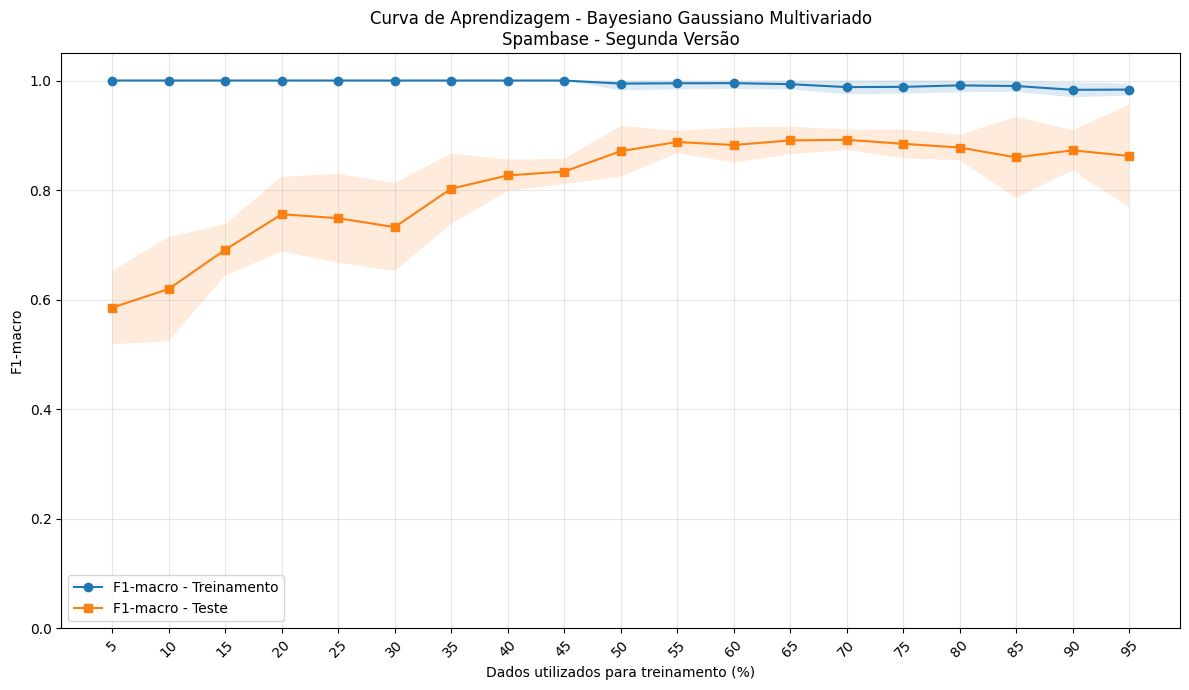


PROCESSO CONCLUÍDO!

Arquivos salvos:

1. Resultados de todas as repetições:
/content/drive/MyDrive/Projeto_emails_ML/resultados_questao_2/curva_gaussiano_repeticoes.csv

2. Resumo das médias e desvios padrão:
/content/drive/MyDrive/Projeto_emails_ML/resultados_questao_2/curva_aprendizagem_gaussiano.csv

3. Gráfico da curva de aprendizagem:
/content/drive/MyDrive/Projeto_emails_ML/resultados_questao_2/curva_aprendizagem_gaussiano.png

Total esperado de avaliações: 95
Total realizado: 95


In [24]:

# ============================================================
# CURVA DE APRENDIZAGEM
# BAYESIANO GAUSSIANO MULTIVARIADO
# SPAMBASE - SEGUNDA VERSÃO (RÓTULOS DO DOUBLE K-MEANS)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. CONFERIR OS DADOS
# ------------------------------------------------------------

# X: atributos dos e-mails
# y_clusters: rótulos dos clusters obtidos pelo Double K-means

X_array = X.to_numpy(dtype=float) if hasattr(X, "to_numpy") else np.asarray(X, dtype=float)
y = np.asarray(y_clusters)

print("Formato dos dados:", X_array.shape)
print("Total de exemplos:", len(y))
print("\nQuantidade de exemplos por classe:")

classes, quantidades = np.unique(y, return_counts=True)

for classe, quantidade in zip(classes, quantidades):
    print(f"Classe {classe}: {quantidade} exemplos")

# Verificar se X e y têm o mesmo número de exemplos
assert X_array.shape[0] == len(y), (
    "Erro: X e y_clusters precisam ter o mesmo número de exemplos."
)

# Verificar se o classificador já foi definido
try:
    BayesGaussianoMultivariado
except NameError:
    raise NameError(
        "Execute primeiro a célula que define a classe "
        "BayesGaussianoMultivariado."
    )

# ------------------------------------------------------------
# 2. DEFINIR AS CONFIGURAÇÕES
# ------------------------------------------------------------

# Proporções de treinamento: 5%, 10%, ..., 95%
proporcoes_treinamento = range(5, 100, 5)

# Número de divisões aleatórias por proporção
numero_repeticoes = 5

# Armazenar resultados individuais
resultados_curva = []

# ------------------------------------------------------------
# 3. EXECUTAR A CURVA DE APRENDIZAGEM
# ------------------------------------------------------------

for percentual_treino in proporcoes_treinamento:

    print(f"\nProcessando treinamento com {percentual_treino}% dos dados...")

    for repeticao in range(numero_repeticoes):

        # Dividir os dados preservando a proporção das classes.
        # O estado aleatório muda em cada repetição.
        X_treino, X_teste, y_treino, y_teste = train_test_split(
            X_array,
            y,
            train_size=percentual_treino / 100,
            stratify=y,
            random_state=42 + repeticao
        )

        # Criar um novo classificador para esta divisão
        modelo = BayesGaussianoMultivariado(
            regularizacao=1e-6
        )

        # Treinar apenas com os dados de treinamento
        modelo.fit(X_treino, y_treino)

        # Fazer previsões nos dois conjuntos
        previsoes_treino = modelo.predict(X_treino)
        previsoes_teste = modelo.predict(X_teste)

        # Calcular F1-macro
        f1_treino = f1_score(
            y_treino,
            previsoes_treino,
            average="macro",
            zero_division=0
        )

        f1_teste = f1_score(
            y_teste,
            previsoes_teste,
            average="macro",
            zero_division=0
        )

        # Guardar resultados
        resultados_curva.append({
            "percentual_treinamento": percentual_treino,
            "percentual_teste": 100 - percentual_treino,
            "repeticao": repeticao + 1,
            "f1_macro_treinamento": f1_treino,
            "f1_macro_teste": f1_teste,
            "n_treinamento": len(y_treino),
            "n_teste": len(y_teste)
        })

# ------------------------------------------------------------
# 4. CRIAR A TABELA DOS RESULTADOS INDIVIDUAIS
# ------------------------------------------------------------

df_curva_repeticoes = pd.DataFrame(resultados_curva)

print("\n" + "=" * 65)
print("RESULTADOS INDIVIDUAIS")
print("=" * 65)

display(df_curva_repeticoes.head(10))

print("\nTotal de avaliações:", len(df_curva_repeticoes))

# Esperado: 19 proporções x 5 repetições = 95 avaliações
assert len(df_curva_repeticoes) == 95

# ------------------------------------------------------------
# 5. CALCULAR MÉDIA E DESVIO PADRÃO POR PROPORÇÃO
# ------------------------------------------------------------

df_curva = (
    df_curva_repeticoes
    .groupby(
        ["percentual_treinamento", "percentual_teste"],
        as_index=False
    )
    .agg(
        f1_treinamento_medio=("f1_macro_treinamento", "mean"),
        f1_treinamento_desvio=("f1_macro_treinamento", "std"),
        f1_teste_medio=("f1_macro_teste", "mean"),
        f1_teste_desvio=("f1_macro_teste", "std"),
        repeticoes=("repeticao", "count")
    )
)

print("\n" + "=" * 65)
print("RESUMO DA CURVA DE APRENDIZAGEM")
print("=" * 65)

display(df_curva.round(4))

# ------------------------------------------------------------
# 6. GERAR O GRÁFICO
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

# Curva do conjunto de treinamento
plt.plot(
    df_curva["percentual_treinamento"],
    df_curva["f1_treinamento_medio"],
    marker="o",
    label="F1-macro - Treinamento"
)

# Curva do conjunto de teste
plt.plot(
    df_curva["percentual_treinamento"],
    df_curva["f1_teste_medio"],
    marker="s",
    label="F1-macro - Teste"
)

# Faixas de um desvio padrão para visualizar a variação
plt.fill_between(
    df_curva["percentual_treinamento"],
    np.clip(
        df_curva["f1_treinamento_medio"]
        - df_curva["f1_treinamento_desvio"].fillna(0),
        0, 1
    ),
    np.clip(
        df_curva["f1_treinamento_medio"]
        + df_curva["f1_treinamento_desvio"].fillna(0),
        0, 1
    ),
    alpha=0.15
)

plt.fill_between(
    df_curva["percentual_treinamento"],
    np.clip(
        df_curva["f1_teste_medio"]
        - df_curva["f1_teste_desvio"].fillna(0),
        0, 1
    ),
    np.clip(
        df_curva["f1_teste_medio"]
        + df_curva["f1_teste_desvio"].fillna(0),
        0, 1
    ),
    alpha=0.15
)

plt.title(
    "Curva de Aprendizagem - Bayesiano Gaussiano Multivariado\n"
    "Spambase - Segunda Versão"
)

plt.xlabel("Dados utilizados para treinamento (%)")
plt.ylabel("F1-macro")
plt.xticks(list(proporcoes_treinamento), rotation=45)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# ------------------------------------------------------------
# 7. SALVAR ARQUIVOS NO GOOGLE DRIVE
# ------------------------------------------------------------

pasta_resultados = (
    "/content/drive/MyDrive/Projeto_emails_ML/"
    "resultados_questao_2"
)

os.makedirs(pasta_resultados, exist_ok=True)

# Arquivo com todas as repetições
caminho_repeticoes = os.path.join(
    pasta_resultados,
    "curva_gaussiano_repeticoes.csv"
)

df_curva_repeticoes.to_csv(
    caminho_repeticoes,
    index=False
)

# Arquivo com as médias e os desvios padrão
caminho_resumo = os.path.join(
    pasta_resultados,
    "curva_aprendizagem_gaussiano.csv"
)

df_curva.to_csv(
    caminho_resumo,
    index=False
)

# Salvar o gráfico
caminho_grafico = os.path.join(
    pasta_resultados,
    "curva_aprendizagem_gaussiano.png"
)

plt.savefig(
    caminho_grafico,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. CONFIRMAR OS ARQUIVOS SALVOS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PROCESSO CONCLUÍDO!")
print("=" * 65)

print("\nArquivos salvos:")

print("\n1. Resultados de todas as repetições:")
print(caminho_repeticoes)

print("\n2. Resumo das médias e desvios padrão:")
print(caminho_resumo)

print("\n3. Gráfico da curva de aprendizagem:")
print(caminho_grafico)

print("\nTotal esperado de avaliações: 95")
print("Total realizado:", len(df_curva_repeticoes))


## KNN
##### distâncias Euclidiana, City-Block e Chebishev para definir a vizinhança. Use validação cruzada para fixar o o número de vizinhos k e a distância.